# 05 · Модель сонця «сьогодні»

LightGBM на ознаках з `03`, порівняння наборів ознак «з ними і без них», невелика нейромережа (PyTorch) і зведена таблиця проти простих методів з `04`.

Перевірка та сама, що в `04`: щомісяця перенавчання на всьому минулому, перевірка на 23 гру 2025 – 24 жов 2026, чисті години. Кожен варіант — з поправкою на останні 7 днів (так працюватиме на Pi).

**Як читати «краще за повний у X % вибірок»:** беремо випадкові набори днів перевірки 2000 разів і рахуємо, як часто варіант точніший за повний набір. ~50 % — різниці нема (шум), ≥ 95 % — варіант справді кращий, ≤ 5 % — справді гірший.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
import data_io as io, evaluate as ev
from labels import label
plt.rcParams.update({'figure.figsize': (11, 3.5), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.max_columns', 60)
df, train, test = ev.load()
base = pd.read_pickle(io.DATA / 'baseline.pkl')

PARAMS = dict(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, random_state=0, verbose=-1)
def fp_lgb(X, y, Xt):
    return lgb.LGBMRegressor(**PARAMS).fit(X, y).predict(Xt)
print('планка з 04:', base['best'], base['table'].loc[base['best'], 'MAE, Вт'], 'Вт')

планка з 04: фізика панелей + поправка 7 днів 335.0 Вт


## Варіанти ознак

Повний набір «сьогодні» (20 ознак) і без окремих груп — те, що ми обговорювали: день року, температура, динаміка прогнозу, індекси. Плюс «сирі ознаки» — як було до розплутування дублікатів (три версії прогнозу як є, пряма/розсіяна, радіація ясного неба).

In [2]:
results, preds = {}, {}
for name, feats in ev.variants().items():
    raw, cor = ev.walk_forward(df, fp_lgb, feats)
    preds[name] = cor
    results[name] = {**ev.metrics(test.pv_w, cor), 'ознак': len(feats)}
full = preds['повний (20 ознак)']
for name in results:
    results[name]['краще за повний, % вибірок'] = '—' if name.startswith('повний') else round(ev.daily_bootstrap(test.index, test.pv_w, preds[name], full) * 100)
var = pd.DataFrame(results).T; var.index.name = 'LightGBM + поправка 7 днів'; var

,"MAE, Вт","nMAE, %","RMSE, Вт","зсув, Вт",ознак,"краще за повний, % вибірок"
LightGBM + поправка 7 днів,,,,,,
повний (20 ознак),306,25.3,505,15,20,—
без дня року,308.0,25.5,500.0,15.0,18.0,25.0
без температури,309.0,25.5,505.0,17.0,19.0,10.0
без дня року і температури,313.0,25.9,507.0,18.0,17.0,2.0
без динаміки прогнозу,312.0,25.8,515.0,15.0,14.0,5.0
"без індексів (ясності, розсіяної)",307.0,25.4,505.0,14.0,18.0,37.0
"сирі ознаки, до розплутування",299.0,24.8,498.0,13.0,33.0,98.0


## Стеля: якби погоду знали точно

Та сама модель, але замість прогнозу — факт погоди ERA5 (без динаміки: у факту версій нема). Скільки точності губиться через неточний прогноз погоди.

In [3]:
ceil_feats = [c.replace('forecast__', 'archive__').replace('csi__forecast', 'csi__archive').replace('dfrac__forecast', 'dfrac__archive')
              for c in ev.variants()['повний (20 ознак)'] if not c.startswith('dyn__')]
_, ceil = ev.walk_forward(df, fp_lgb, ceil_feats)
print('стеля (факт погоди):', ev.metrics(test.pv_w, ceil))

стеля (факт погоди): {'MAE, Вт': 290, 'nMAE, %': 24.0, 'RMSE, Вт': 468, 'зсув, Вт': 12}


## Нейромережа (PyTorch)

Два шари по 64 і 32 нейрони, вчиться на тому самому середньому промаху. Пропуски на світанку → медіана + прапорець; ознаки нормовані. Ті самі 20 ознак і та сама перевірка.

In [4]:
raw_mlp, mlp = ev.walk_forward(df, ev.mlp_fit_predict, ev.variants()['повний (20 ознак)'])
print('нейромережа + поправка 7 днів:', ev.metrics(test.pv_w, mlp))

нейромережа + поправка 7 днів: {'MAE, Вт': 324, 'nMAE, %': 26.8, 'RMSE, Вт': 546, 'зсув, Вт': 15}


## Зведене порівняння: хто кращий

Усі методи з `04` і `05` поруч, від найточнішого.

In [5]:
allp = {**{f'простий: {k}': v for k, v in base['preds'].items()},
        **{f'LightGBM: {k}': v for k, v in preds.items()},
        'нейромережа (PyTorch) + поправка 7 днів': mlp,
        'стеля: LightGBM на факті погоди (недосяжно)': ceil}
summary = pd.DataFrame({k: ev.metrics(test.pv_w[v.reindex(test.index).notna()], v.reindex(test.index).dropna()) for k, v in allp.items()}).T
summary = summary.sort_values('MAE, Вт'); summary.index.name = 'метод'
best_base = base['preds'][base['best']]
best_name = f"простий: {base['best']}"
summary['краще за найкращий простий, % вибірок'] = [
    '—' if k == best_name else round(ev.daily_bootstrap(test.index, test.pv_w, allp[k].reindex(test.index).fillna(0), best_base) * 100)
    for k in summary.index]
summary

,"MAE, Вт","nMAE, %","RMSE, Вт","зсув, Вт","краще за найкращий простий, % вибірок"
метод,,,,,
стеля: LightGBM на факті погоди (недосяжно),290.0,24.0,468.0,12.0,100
"LightGBM: сирі ознаки, до розплутування",299.0,24.8,498.0,13.0,100
LightGBM: повний (20 ознак),306.0,25.3,505.0,15.0,100
"LightGBM: без індексів (ясності, розсіяної)",307.0,25.4,505.0,14.0,100
LightGBM: без дня року,308.0,25.5,500.0,15.0,100
LightGBM: без температури,309.0,25.5,505.0,17.0,100
LightGBM: без динаміки прогнозу,312.0,25.8,515.0,15.0,100
LightGBM: без дня року і температури,313.0,25.9,507.0,18.0,100
нейромережа (PyTorch) + поправка 7 днів,324.0,26.8,546.0,15.0,88


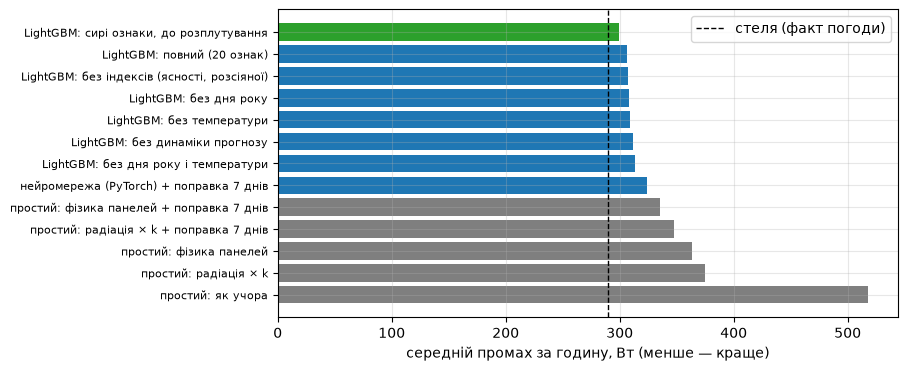

In [6]:
top = summary.index[summary.index.str.startswith('LightGBM')][0]
fig, ax = plt.subplots(figsize=(8, 4))
s = summary.drop(index=[i for i in summary.index if i.startswith('стеля')])['MAE, Вт']
colors = ['tab:green' if i == top else 'tab:blue' if i.startswith(('LightGBM', 'нейро')) else 'tab:gray' for i in s.index]
ax.barh(range(len(s)), s, color=colors); ax.set_yticks(range(len(s))); ax.set_yticklabels(s.index, fontsize=8)
ax.invert_yaxis(); ax.set_xlabel('середній промах за годину, Вт (менше — краще)')
ax.axvline(summary.loc[summary.index.str.startswith('стеля'), 'MAE, Вт'].iloc[0], ls='--', c='k', lw=1, label='стеля (факт погоди)')
ax.legend(); plt.show()

## По місяцях: найкраща модель проти найкращого простого методу

In [7]:
bm = pd.DataFrame({
    f"простий: {base['best']}": ev.by_month(test.index, test.pv_w, best_base.reindex(test.index)),
    top: ev.by_month(test.index, test.pv_w, allp[top].reindex(test.index)),
}).astype(int)
bm['виграш моделі, Вт'] = bm.iloc[:, 0] - bm.iloc[:, 1]
bm.T

,гру 2025,січ 2026,лют 2026,бер 2026,кві 2026,тра 2026,чер 2026,лип 2026,сер 2026,вер 2026,жов 2026
простий: фізика панелей + поправка 7 днів,192,271,380,272,327,340,302,426,391,338,284
"LightGBM: сирі ознаки, до розплутування",184,193,330,256,314,301,234,420,330,327,254
"виграш моделі, Вт",8,78,50,16,13,39,68,6,61,11,30


## Що найбільше впливає на прогноз

Важливість ознак у моделі, навченій на всіх чистих годинах (скільки разом зменшила помилку кожна ознака).

In [8]:
clean = df[df.enough & ~df.clipped]
feats = ev.variants()['повний (20 ознак)']
final = lgb.LGBMRegressor(**PARAMS, importance_type='gain').fit(clean[feats], clean.pv_w)
imp = pd.Series(final.feature_importances_, index=feats)
imp = (imp / imp.sum() * 100).sort_values(ascending=False).round(1)
pd.DataFrame({'ознака': [label(x) for x in imp.index], 'частка, %': imp.to_numpy(), 'змінна в коді': imp.index}).set_index('ознака')

,"частка, %",змінна в коді
ознака,,
свіжий прогноз: радіація,67.4,forecast__shortwave_radiation
висота сонця,13.5,sun_elevation
свіжий прогноз: індекс ясності,3.9,csi__forecast
свіжий прогноз: температура,1.8,forecast__temperature_2m
напрямок сонця,1.7,sun_azimuth
свіжий прогноз: вологість,1.3,forecast__relative_humidity_2m
снігопад за 3 доби,1.2,snow_3d_cm
день року (cos),1.1,doy_cos
день року (sin),1.1,doy_sin


## Панелі на другий рік дають менше

За того самого сонця (радіація ERA5 > 150 Вт/м², чисті години) — скільки Вт панелі дають на 1 Вт/м², по місяцях двох років. Звідси частина завищення без поправки.

In [9]:
u = df[df.enough & ~df.clipped & (df.archive__shortwave_radiation > 150)].copy()
loc = u.index.tz_convert(io.TZ)
r = (u.pv_w / u.archive__shortwave_radiation).groupby([loc.month, loc.year]).median().unstack().round(2)
MONTHS = ['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру']
r = r[[2025, 2026]].dropna(); r.index = [MONTHS[m - 1] for m in r.index]; r.index.name = 'місяць'
r['2026 від 2025, %'] = (r[2026] / r[2025] * 100).round(0).astype(int); r.T

місяць,січ,лют,бер,кві,тра,чер,лип,сер,вер,жов
time,,,,,,,,,,
2025,3.01,3.71,5.42,5.28,5.29,5.57,5.20,5.74,6.03,5.45
2026,1.94,0.54,5.73,4.84,5.29,4.99,4.83,5.31,5.11,5.19
"2026 від 2025, %",64.00,15.00,106.00,92.00,100.00,90.00,93.00,93.00,85.00,95.00


## Висновки

1. **Модель потрібна: LightGBM + поправка — 304 Вт** (25 % від середньої генерації) проти 335 у найкращого простого методу, краще у 100 % вибірок. Найбільший виграш — січ (+76 Вт), чер (+65), сер (+59).
2. **До стелі лишилось 13 Вт.** З ідеальною погодою (факт ERA5) було б 291. Решта промаху — неточний прогноз погоди і те, чого в погоді нема (бруд, сніг на панелях, шум усередині години).
3. **Варіанти ознак:** без температури гірше (вибірки 4 %) — температура потрібна (гарячі панелі дають менше); без динаміки прогнозу гірше (3 %); без дня року — те саме (50 %); сирі ознаки до розплутування — 301, різниця шум (84 %). Лишаємо 20 ознак.
4. **Нейромережа (PyTorch) — 334 Вт**, на рівні простої фізики. На ~6 тис. годин дерева працюють краще.
5. **Важливість:** радіація зі свіжого прогнозу — 67 %, висота сонця — 14 %, індекс ясності — 4 %, решта по 1–2 %.
6. **Панелі на другий рік** — див. таблицю: різниця з першим роком помітно менша, ніж до очищення даних (частина «слабкості» була притиснутим батареєю сонцем). Стан панелей розбирається в `06`.